# Lecture 17, Statistical background for downscaling

> The small amount of probability and statistics behind every bias-correction and downscaling method in Lectures 18&ndash;23

Nobody knows how much rain will fall next January. But past Januaries tell us what is *likely*: some amounts are common, some are rare. Statistics gives us a **curve** that describes this, a way to **fit** the curve to data, and a way to **draw** new random Januaries from it. Downscaling uses exactly these three things, so we learn them once here, with the symbols of Lee & Singh (2019), Chapter 2.

By the end of this lecture you should be able to:

1. explain in plain words the terms in the box below (mean, quantile, CDF and so on),
2. say which curve (normal, gamma, exponential, GEV and others) suits temperature, rainfall amounts and yearly maxima,
3. fit a curve to a sample by moments and by maximum likelihood, by hand for a small example,
4. draw a histogram and an empirical CDF,
5. use a correlation to say what the station temperature is likely to be, given the model temperature,
6. make random numbers and turn them into random rainfall.

All data are **synthetic**: 26 January rainfall totals and 40 model&ndash;station temperature pairs, in `data/downscaling/lec17/`.

In [1]:
# Google Colab setup: install the packages this notebook uses.
# Runs only on Colab; skipped in Binder or a local Jupyter install.
import sys
if "google.colab" in sys.modules:
    %pip install -q numpy pandas matplotlib scipy

## Statistics words you need

Take five January rainfalls (mm): **10, 20, 20, 30, 70**. Each word below is shown on these numbers.

| Word | Everyday meaning | With the five numbers |
|:--|:--|:--|
| **random variable** $X$ | a quantity we cannot know in advance, such as next January's rain; $x$ is one value of it | $X$ = next January's rain, $x$ = 30 mm |
| **mean** $\mu$ (from data: $\bar x$) | the average | $(10+20+20+30+70)/5=30$ mm |
| **variance** $\sigma^2$ (from data: $s^2$) | the average squared distance from the mean; big means very spread out (for data we divide by $n-1$) | distances $-20,-10,-10,0,40$; squares $400,100,100,0,1600$; sum $2200$; $s^2=2200/4=550$ mm$^2$ |
| **standard deviation** $\sigma$ | square root of the variance, back in mm | $\sqrt{550}=23.5$ mm |
| **skewness** $\gamma$ | which side has the long tail: positive means a few very large values | the single 70 mm drags the tail to the right: positive |
| **CDF** $F(x)$ | the chance that the value is *at most* $x$ | 3 of 5 values are $\le 20$, so $F(20)=0.6$ |
| **probability density** $f(x)$ | the height of the curve; the *area* under it between two values is the chance of landing there | the curve is the smooth version of a histogram |
| **quantile** (percentile) | the value below which a given fraction of the values fall | the 0.5 quantile (median) is 20 mm; the 0.9 quantile is the 90th percentile |
| **likelihood** | how plausible the observed data are if the curve has the chosen parameters; we pick the parameters that make it largest | see the worked example |
| **covariance** $\gamma_{12}$ and **correlation** $\rho$ | do two variables rise and fall together? The correlation is the unit-free version, from $-1$ to $1$ | pairs $(1,2),(2,3),(3,7)$: covariance $5/3=1.67$, correlation $0.94$ (strongly together) |
| **plotting position** | the chance we give to the $i$-th smallest value of $n$, namely $i/(n+1)$ | for $n=5$: $1/6,\,2/6,\dots,5/6$; the largest is $0.83$, not 1 |

*What this means for hydrology:* a design rainfall is a quantile (for example the 0.99 quantile), and the mean and spread tell us how risky a season is.

## Notation

The symbols are those of Lee & Singh (2019), Chapter 2. **Code rule:** the book's symbol written in ASCII, subscripts after an underscore, a bar as `_bar`, a hat as `_hat` (the book writes a hat for every estimate; the code uses it where an estimate could be confused with a parameter).

| Book symbol | Meaning | Code / spreadsheet |
|:--|:--|:--|
| $X$, $x$; $F_X(x)$, $f_X(x)$, $p_X(x)$ | random variable and value; CDF, pdf, PMF | `x`, `F`, `f`, `p` |
| $\mu$, $\sigma^2$, $\sigma$, $\delta_X=\sigma_X/\mu_X$, $\gamma$ | mean, variance, standard deviation, coefficient of variation, coefficient of skewness | `mu`, `sigma2`, `sigma`, `delta`, `gamma_sk` |
| $p$, $n$ | Bernoulli or binomial probability, number of trials or of data | `p`, `n` |
| $\zeta=E(\ln X)$, $\varsigma=\sqrt{\mathrm{Var}(\ln X)}$ | lognormal parameters | `zeta`, `varsigma` |
| $\alpha$ | **exponential** scale (equal to the mean) | `alpha` |
| $\alpha$, $\beta$ | **gamma** shape and scale | `alpha`, `beta` |
| $\alpha$, $\beta$, $x_0$ | **GEV** scale, shape, location (Gumbel: $\alpha$, $x_0$) | `alpha`, `beta`, `x_0` |
| $T$, $x_T$ | return period, quantile of return period $T$ | `T`, `x_T` |
| $\bar{x}$, $s^2$ | sample mean and variance | `x_bar`, `s2` |
| $LL$ | log-likelihood (the logarithm of the likelihood) | `LL` |
| $n_c$, $\Delta x$, $n(i)$, $\hat p(i)$, $\hat F(i)$, $\hat f(i)$ | histogram: classes, class width, count, relative frequency, empirical CDF, empirical density | `n_c`, `delta_x`, `n_i`, `p_hat_i`, `F_hat_i`, `f_hat_i` |
| $x_{(i)}$, $\hat F(x_{(i)})=i/(n+1)$ | ordered data, plotting position | `x_ord`, `pp` |
| $\boldsymbol\mu$, $\boldsymbol\Sigma$, $N_p(\boldsymbol\mu,\boldsymbol\Sigma)$ | mean vector, covariance matrix, multivariate normal | (not coded) |
| $\gamma_{12}$, $\rho$, $\hat\gamma_{12}$, $\hat\rho_{12}$ | covariance and correlation of $X_1,X_2$ and their estimates | `gamma_12_hat`, `rho_12_hat` |
| $a$, $b$, $M$, $x_j$, $u_j$ | generator increment, multiplier, modulus, integer, uniform number | `a`, `b`, `M`, `x_lcg`, `u` |

In the temperature example $X_1$ is the **station** temperature (the quantity we want) and $X_2$ the **model** temperature (what we know), so the book's conditional $f(x_1\mid x_2)$ reads "station given model".

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats, special, optimize

BASE = "data/downscaling/lec17/"
RAW = "https://raw.githubusercontent.com/drvivekhydro/hydroclimatology/main/data/downscaling/lec17/"

def load(name):
    # Read a CSV from the repository folder, or from GitHub if it is not there (e.g. on Colab).
    try:
        return pd.read_csv(BASE + name)
    except FileNotFoundError:
        return pd.read_csv(RAW + name)

x = load("january_precip.csv")["precip_mm"].to_numpy()    # 26 January totals [mm], synthetic
n = len(x)
temps = load("seasonal_temperature_pairs.csv")             # 40 seasons, synthetic
x_1 = temps["station_T_degC"].to_numpy()                   # X_1: station temperature
x_2 = temps["model_T_degC"].to_numpy()                     # X_2: model temperature
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3, "axes.spines.top": False, "axes.spines.right": False})
print(f"n = {n} Januaries, first eight: {x[:8]} mm;  {len(x_1)} temperature pairs")

n = 26 Januaries, first eight: [24. 41. 18. 66. 35. 52. 29. 47.] mm;  40 temperature pairs


## 2.1.1 Probabilistic theory (Ch. 2.1.1)

### 2.1.1.1 Probability density function and cumulative distribution function

A **random variable** $X$ (capital letter) is a quantity that depends on chance, such as next January's rain; a particular value is written $x$. Its **cumulative distribution function (CDF)** is the chance of not exceeding $x$,

$$F_X(x)=P(X\le x).\qquad (2.1)$$

For a variable with separate possible values (a *discrete* variable, such as the number of wet days) the **probability mass function (PMF)** is $p_X(x)=P(X=x)$ and $F_X(x)=\sum_{x_i\le x}p_X(x_i)$ (2.2). For a *continuous* variable (rain in mm) any single value has probability zero, so we use the **probability density function (pdf)**, the slope of the CDF,

$$f_X(x)=\frac{dF_X(x)}{dx}.\qquad (2.3)$$

*Plain gloss:* the area under the pdf between two values is the chance of landing between them; the CDF is the running total of that area.

### 2.1.1.2 Descriptors of random variables

The **mean** $\mu=E[X]=\int x f_X(x)\,dx$ (2.4) is the centre. The **mode** is the most likely value (the peak of the pdf) and the **median** $x_m$ satisfies $F_X(x_m)=0.5$. The **variance** $\sigma^2=E[(X-\mu)^2]$ (2.5) measures the spread, $\sigma=\sqrt{\mathrm{Var}(X)}$ is the standard deviation, and the **coefficient of variation** $\delta_X=\sigma_X/\mu_X$ (2.6) is the spread relative to the centre. The **coefficient of skewness** $\gamma=E[(X-\mu)^3]/\sigma^3$ (2.8) is positive when the right tail is long, as for rainfall. (The kurtosis $g$, Eq. 2.10, describes peakedness; we do not use it.)

*What this means for hydrology:* the mean and spread say how wet a typical season is and how much it varies; a design rainfall is a quantile read from the CDF.

## 2.1.2 Discrete probability distributions (Ch. 2.1.2)

**Bernoulli (2.1.2.1).** One trial with two outcomes, occurrence ($x=1$) with probability $p$ or not ($x=0$), for example a wet day: $p_X(x)=p^x(1-p)^{1-x}$ (2.11), with mean $p$ and variance $p(1-p)$ (2.12&ndash;2.13).

**Binomial (2.1.2.2).** The number of occurrences $x$ in $n$ independent Bernoulli trials with the same $p$: $p_X(x)=\binom{n}{x}p^x(1-p)^{n-x}$ (2.14), with mean $np$ and variance $np(1-p)$ (2.15&ndash;2.16). For example, with $p=0.3$ the expected number of wet days in 30 days is $30\times0.3=9$.

## 2.1.3 Continuous probability distributions (Ch. 2.1.3)

Rain and flow have no negative values and a long right tail, so the symmetric normal is often a poor choice for them; the book uses the exponential, lognormal and gamma for amounts and the Gumbel and GEV for extremes.

### 2.1.3.1 Normal and lognormal distributions

The **normal** pdf, with mean $\mu$ and standard deviation $\sigma$ as its two parameters, is

$$f_X(x)=\frac{1}{\sigma\sqrt{2\pi}}\exp\!\left[-\frac{(x-\mu)^2}{2\sigma^2}\right].\qquad (2.17)$$

Larger $\mu$ moves the bell to the right; larger $\sigma$ widens it. The variable $Z=(X-\mu)/\sigma$ has $\mu=0$, $\sigma=1$ (the *standard normal*, pdf 2.18) with CDF $\Phi(z)$ (2.19). The **lognormal** is the normal applied to $\ln X$:

$$f_X(x)=\frac{1}{\varsigma\,x\sqrt{2\pi}}\exp\!\left[-\frac{(\ln x-\zeta)^2}{2\varsigma^2}\right],\quad \zeta=E(\ln X),\ \varsigma=\sqrt{\mathrm{Var}(\ln X)}.\qquad (2.20)$$

### 2.1.3.2 Exponential and gamma distributions

The **exponential** has one parameter $\alpha$:

$$f_E(x)=\frac1\alpha e^{-x/\alpha},\qquad F_E(x)=1-e^{-x/\alpha},\qquad x=-\alpha\ln[1-F_E(x)],\qquad (2.21\text{&ndash;}2.23)$$

and its mean is $\mu=\alpha$ (2.24). The **gamma**, widely used for precipitation, has shape $\alpha$ and scale $\beta$:

$$f_G(x)=\frac{x^{\alpha-1}e^{-x/\beta}}{\Gamma(\alpha)\,\beta^{\alpha}},\qquad \mu=\alpha\beta,\qquad \sigma^2=\alpha\beta^2.\qquad (2.25,\ 2.27,\ 2.28)$$

Solving the last two for the parameters gives the moment estimates

$$\beta=\frac{\sigma^2}{\mu},\qquad \alpha=\frac{\mu}{\beta}.\qquad (2.29\text{ and }2.30)$$

The book reuses $\alpha$ and $\beta$ with a different meaning in each family, so check which distribution you are in. *Plain gloss:* the gamma with shape $\alpha<1$ rises steeply at zero (many light-rain days), with larger $\alpha$ it has a hump (typical monthly totals), and $\alpha=1$ is the exponential (see the figure).

### 2.1.3.3 GEV and Gumbel distributions

For yearly maxima the book uses the generalized extreme value (**GEV**) distribution with scale $\alpha$, shape $\beta$ and location $x_0$:

$$f(x)=\frac1\alpha\left[1-\beta\left(\frac{x-x_0}{\alpha}\right)\right]^{(1/\beta)-1}F(x),\qquad F(x)=\exp\left\{-\left[1-\beta\left(\frac{x-x_0}{\alpha}\right)\right]^{1/\beta}\right\}.\qquad (2.32\text{ and }2.33)$$

For $\beta=0$ it becomes the **Gumbel** (type 1) distribution, $F(x)=\exp\{-\exp[-(x-x_0)/\alpha]\}$; $\beta<0$ gives the heavy-tailed type 2 and $\beta>0$ the type 3 (Weibull) with an upper limit. **Sign convention:** this is the opposite of the usual statistics convention, $\xi=-\beta$ (so the usual heavy tail is $\xi>0$); `scipy.stats.genextreme(c=...)` uses the book's sign, $c=\beta$. The quantile for return period $T$ (non-exceedance probability $1-1/T$) is

$$x_T=x_0+\frac{\alpha}{\beta}\left\{1-\left[-\ln\!\left(1-\frac1T\right)\right]^{\beta}\right\}\ \text{(GEV, 2.34)},\qquad x_T=x_0-\alpha\ln\!\left[-\ln\!\left(1-\frac1T\right)\right]\ \text{(Gumbel, 2.35)}.$$

*Plain gloss:* the "100-year rain" is exceeded on average once in $T=100$ years, that is, with probability 0.01 in any year.

*What this means for hydrology:* the choice of curve decides how often the model produces a very wet day or year; the printout below the figure shows that a heavy-tailed GEV gives a far larger 100-year rain than a Gumbel with the same centre.

T =

 [  2  10  50 100] years;  Gumbel x_T = [ 55.5  83.8 108.5 119. ] mm;  GEV (beta = -0.25) x_T = [ 55.8  95.3 149.1 179.5] mm


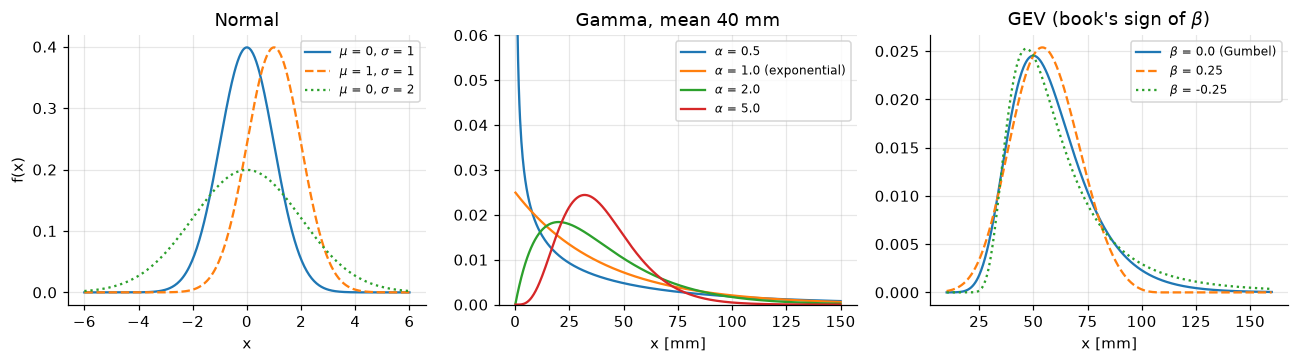

In [3]:
fig, ax = plt.subplots(1, 3, figsize=(12, 3.4))

# Normal: N(0,1), a shifted mean, a larger standard deviation
zz = np.linspace(-6, 6, 400)
for (m_, s_, ls) in ((0, 1, "-"), (1, 1, "--"), (0, 2, ":")):
    ax[0].plot(zz, stats.norm.pdf(zz, m_, s_), ls, label=f"$\\mu$ = {m_}, $\\sigma$ = {s_}")
ax[0].set(title="Normal", xlabel="x", ylabel="f(x)"); ax[0].legend(fontsize=8)

# Gamma with mean alpha*beta = 40 mm; shape alpha = 1 is the exponential
xg = np.linspace(0.1, 150, 500)
for a_ in (0.5, 1.0, 2.0, 5.0):
    ax[1].plot(xg, stats.gamma.pdf(xg, a_, scale=40 / a_), label=f"$\\alpha$ = {a_}" + (" (exponential)" if a_ == 1 else ""))
ax[1].set(title="Gamma, mean 40 mm", xlabel="x [mm]", ylim=(0, 0.06)); ax[1].legend(fontsize=8)

# GEV with the book's sign: beta = scipy's c
x_0, alpha_g = 50.0, 15.0
xe = np.linspace(10, 160, 500)
for beta_g, ls in ((0.0, "-"), (0.25, "--"), (-0.25, ":")):
    F_book = np.exp(-np.clip(1 - beta_g * (xe - x_0) / alpha_g, 0, None) ** (1 / beta_g)) if beta_g else np.exp(-np.exp(-(xe - x_0) / alpha_g))
    assert np.allclose(F_book, stats.genextreme.cdf(xe, c=beta_g, loc=x_0, scale=alpha_g))   # Eq. 2.33 against scipy
    ax[2].plot(xe, stats.genextreme.pdf(xe, c=beta_g, loc=x_0, scale=alpha_g), ls, label=f"$\\beta$ = {beta_g}" + (" (Gumbel)" if beta_g == 0 else ""))
ax[2].set(title="GEV (book's sign of $\\beta$)", xlabel="x [mm]"); ax[2].legend(fontsize=8)
fig.tight_layout()

T = np.array([2, 10, 50, 100])
x_T = x_0 - alpha_g * np.log(-np.log(1 - 1 / T))                              # Eq. 2.35
assert np.allclose(x_T, stats.gumbel_r.ppf(1 - 1 / T, loc=x_0, scale=alpha_g))
x_T_gev = x_0 + alpha_g / -0.25 * (1 - (-np.log(1 - 1 / T)) ** -0.25)         # Eq. 2.34 with beta = -0.25
assert np.allclose(x_T_gev, stats.genextreme.ppf(1 - 1 / T, c=-0.25, loc=x_0, scale=alpha_g))
print("T =", T, "years;  Gumbel x_T =", np.round(x_T, 1), "mm;  GEV (beta = -0.25) x_T =", np.round(x_T_gev, 1), "mm")

## 2.1.4 Parameter estimation for probability distributions (Ch. 2.1.4)

A curve has parameters (such as $\alpha$ and $\beta$) whose true values are unknown, because we only see a finite sample. *Fitting* means estimating them from the sample $x_1,\dots,x_n$; a hat ($\hat\alpha$) marks an estimate.

### 2.1.4.1 Method of moments

The mean and variance are the first and second moments and are tied to the parameters (for example Eq. 2.12 for the Bernoulli). Replace them by the sample mean and variance and solve for the parameters:

$$\bar x=\frac1n\sum_{i=1}^n x_i,\qquad s^2=\frac1{n-1}\sum_{i=1}^n (x_i-\bar x)^2.\qquad (2.36\text{ and }2.37)$$

*Plain gloss:* "make the curve have the same average and spread as the data".

### 2.1.4.2 Maximum likelihood estimation

*Plain gloss:* choose the parameters that make the data we actually saw as plausible as possible. With independent observations the **likelihood** is the product of the pdf heights at the observations, given the parameter set $\theta$,

$$L(x_1,\dots,x_n\mid\theta)=\prod_{i=1}^n f(x_i\mid\theta),\qquad (2.38)$$

and the best $\theta$ is where the derivative of $L$ with respect to each parameter is zero (2.39). Because a product of many small numbers is awkward, the **log-likelihood** is used, which turns the product into a sum:

$$LL(x_1,\dots,x_n\mid\theta)=\sum_{i=1}^n\log f(x_i\mid\theta).\qquad (2.40)$$

Below is a worked example of the book's first example type (Example 2.1: fit the exponential by moments and by maximum likelihood), with eight new numbers.

### Worked example (by hand): exponential fit by moments and by maximum likelihood

**Problem.** Fit the exponential distribution (Eq. 2.21) to the January rainfall (mm) of eight years, $x_i=24,\,41,\,18,\,66,\,35,\,52,\,29,\,47$, with the method of moments and with maximum likelihood.

**Step 1, sample mean (2.36).** *Why:* for the exponential the mean is the parameter ($\mu=\alpha$, Eq. 2.24).
$\bar x=(24+41+18+66+35+52+29+47)/8=312/8=39.0$ mm.

**Step 2, moment estimate.** $\hat\alpha=\bar x=39.0$ mm.

**Step 3, log-likelihood (2.40).** *Why:* it is the sum of $\log f(x_i)$ with $f=\frac1\alpha e^{-x/\alpha}$, so $\log f(x_i)=-\ln\alpha-x_i/\alpha$ and
$LL(\alpha)=-n\ln\alpha-\frac1\alpha\sum x_i$.

**Step 4, find the maximum (2.39).** *Why:* the peak is where the slope is zero.
$dLL/d\alpha=-n/\alpha+\sum x_i/\alpha^2=0$, which gives $\hat\alpha=\sum x_i/n=312/8=39.0$ mm (2.41). The maximum-likelihood estimate equals the moment estimate.

**Step 5, numerical check of the peak.** $LL(30)=-8\ln30-312/30=-27.21-10.40=-37.61$; $LL(39)=-8\ln39-312/39=-29.31-8.00=-37.31$; $LL(50)=-8\ln50-312/50=-31.30-6.24=-37.54$. The largest value is at $\alpha=39$.

**Step 6, the gamma by moments (2.29, 2.30).** *Why:* the gamma has two parameters, so we also need the variance. The distances from the mean are $-15,\,2,\,-21,\,27,\,-4,\,13,\,-10,\,8$, with squares $225,\,4,\,441,\,729,\,16,\,169,\,100,\,64$ adding to $1748$, so $s^2=1748/7=249.71$ mm$^2$. Then $\hat\beta=s^2/\bar x=249.71/39=6.403$ mm and $\hat\alpha=\bar x/\hat\beta=39/6.403=6.091$.

**Answer.** Exponential $\hat\alpha=39.0$ mm by both methods ($LL=-37.31$); gamma by moments $\hat\alpha=6.09$, $\hat\beta=6.40$ mm. In plain words: the typical January is about 39 mm.

In [4]:
x8 = x[:8]
x_bar, s2 = x8.mean(), x8.var(ddof=1)
alpha_E = x_bar                                          # exponential, MOM = MLE
LL_E = -len(x8) * np.log(alpha_E) - x8.sum() / alpha_E
beta_hat, alpha_hat = s2 / x_bar, x_bar / (s2 / x_bar)   # gamma MOM, Eqs. 2.29, 2.30
print(f"x_bar = {x_bar:.2f} mm,  s2 = {s2:.2f} mm^2,  alpha_E = {alpha_E:.2f} mm,  LL = {LL_E:.2f}")
for a_try in (30, 39, 50):
    print(f"  trial alpha = {a_try}: LL = {-len(x8) * np.log(a_try) - x8.sum() / a_try:.2f}")
print(f"gamma MOM: beta_hat = {beta_hat:.3f} mm, alpha_hat = {alpha_hat:.3f}")

x_bar = 39.00 mm,  s2 = 249.71 mm^2,  alpha_E = 39.00 mm,  LL = -37.31
  trial alpha = 30: LL = -37.61
  trial alpha = 39: LL = -37.31
  trial alpha = 50: LL = -37.54
gamma MOM: beta_hat = 6.403 mm, alpha_hat = 6.091


### Gamma by maximum likelihood (the book's Example 2.2, condensed)

The same recipe for the gamma. The log-likelihood is
$LL(\alpha,\beta)=-n\log\Gamma(\alpha)-n\alpha\log\beta+(\alpha-1)\sum\log x_i-\frac1\beta\sum x_i$.
Setting its derivative with respect to $\beta$ to zero gives

$$\hat\beta=\frac{\bar x}{\hat\alpha}\qquad (2.42)$$

(the fitted mean $\alpha\beta$ equals the sample mean). Substituting this into the derivative with respect to $\alpha$ leaves one equation in $\alpha$ (2.43),

$$\ln\alpha-\psi(\alpha)=\ln\bar x-\frac1n\sum_i\ln x_i,$$

where $\psi=\Gamma'/\Gamma$ is the digamma function. It cannot be solved by hand, so a computer finds the root numerically. The next cell does this for the 26 January totals and compares with the moment fit.

*What this means for hydrology:* a fitted curve lets us read off rainfall values that were never observed, but the answer depends on the fitting rule, so we always compare the curve with the data (next section).

In [5]:
# --- parameter estimates for all 26 Januaries ------------------------------------------------------
x_bar, s2 = x.mean(), x.var(ddof=1)
print(f"mean = {x_bar:.2f} mm, sd = {np.sqrt(s2):.2f} mm, skewness = {stats.skew(x, bias=False):.2f}")
alpha_E = x_bar                                                    # exponential (2.41)
beta_mom = s2 / x_bar; alpha_mom = x_bar / beta_mom                # gamma MOM (2.29, 2.30)
rhs = np.log(x_bar) - np.log(x).mean()                             # right side of Eq. 2.43
alpha_mle = optimize.brentq(lambda a_: np.log(a_) - special.digamma(a_) - rhs, 0.05, 500)
beta_mle = x_bar / alpha_mle                                       # Eq. 2.42
LL = lambda dist: dist.logpdf(x).sum()                             # Eq. 2.40
print(f"exponential: alpha = {alpha_E:.2f} mm, LL = {LL(stats.expon(scale=alpha_E)):.2f}")
print(f"gamma MOM  : alpha = {alpha_mom:.3f}, beta = {beta_mom:.2f} mm, LL = {LL(stats.gamma(alpha_mom, scale=beta_mom)):.2f}")
print(f"gamma MLE  : alpha = {alpha_mle:.3f}, beta = {beta_mle:.2f} mm, LL = {LL(stats.gamma(alpha_mle, scale=beta_mle)):.2f}")
a_sp, _, b_sp = stats.gamma.fit(x, floc=0)
print(f"scipy gamma.fit check: alpha = {a_sp:.3f}, beta = {b_sp:.2f}")

mean = 45.18 mm, sd = 22.10 mm, skewness = 2.56
exponential: alpha = 45.18 mm, LL = -125.08
gamma MOM  : alpha = 4.179, beta = 10.81 mm, LL = -111.84
gamma MLE  : alpha = 6.112, beta = 7.39 mm, LL = -110.96
scipy gamma.fit check: alpha = 6.112, beta = 7.39


## 2.1.5 Histogram and empirical distribution (Ch. 2.1.5)

*Plain gloss:* look at the data on their own before trusting a fitted curve. A **histogram** counts how many values fall in each class (bin). For $n$ data in increasing order the book's steps are: (1) find $x_{\min}$ and $x_{\max}$ (and leave a small margin, $x_{\rm Low}$ to $x_{\rm Up}$); (2) choose the number of classes $n_c=1+3.3\log_{10}n$ (2.44), rounded to a whole number, and the class width $\Delta x=(x_{\rm Up}-x_{\rm Low})/n_c$ (2.45, see the note at the end); (3) count the number $n(i)$ of data in class $i$. The relative frequency, empirical CDF and empirical density are

$$\hat p(i)=\frac{n(i)}{n},\qquad \hat F(i)=\sum_{j=1}^{i}\hat p(j),\qquad \hat f(i)=\frac{\hat p(i)}{\Delta x}.\qquad (2.46\text{&ndash;}2.48)$$

$\hat F(i)$ is read at the upper edge of class $i$; its last value is exactly 1, which would say nothing larger can occur. For the sorted data $x_{(1)}\le\dots\le x_{(n)}$ the book therefore uses the **plotting position**

$$\hat F(x_{(i)})=\frac{i}{n+1}\qquad (2.49)$$

(for 26 values the largest gets $26/27=0.96$ instead of 1). The next cell builds the histogram of the 26 January totals, as in the book's Example 2.3, and compares it with the fitted curves: the closer a curve runs to the bars and to the dots, the better it describes the data. The gamma curves follow the data much better than the exponential, which is forced to have a standard deviation equal to its mean; the one very wet January (about 130 mm) inflates $s^2$, so the moment fit has a smaller shape and a longer tail than the maximum-likelihood fit.

*What this means for hydrology:* the same record can give different design values depending on the curve, which is why we look at the data first.

 lower  upper  n(i)  p_hat(i)  f_hat(i)  F_hat(i)
  10.0   31.0     5     0.192    0.0092     0.192
  31.0   52.0    14     0.538    0.0256     0.731
  52.0   73.0     6     0.231    0.0110     0.962
  73.0   94.0     0     0.000    0.0000     0.962
  94.0  115.0     0     0.000    0.0000     0.962
 115.0  136.0     1     0.038    0.0018     1.000


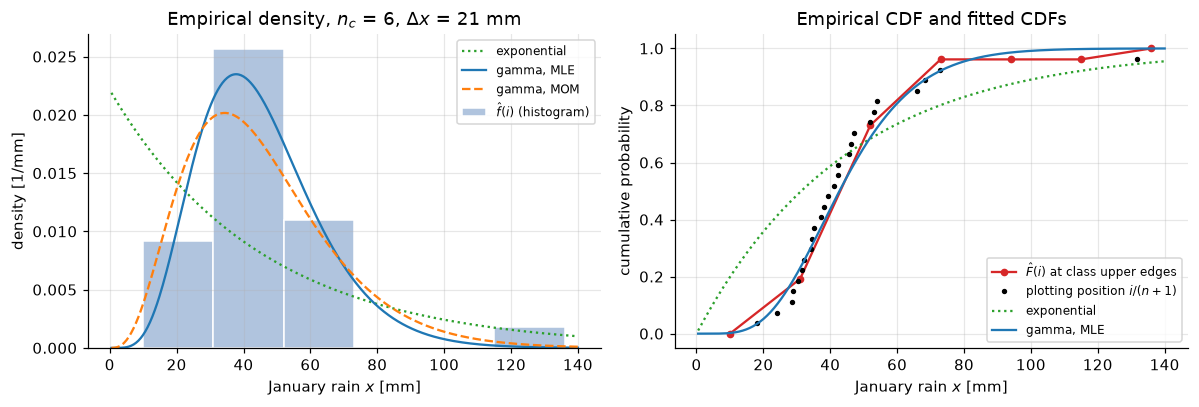

In [6]:
# --- histogram (2.44-2.48) -------------------------------------------------------------------------
n_c = int(round(1 + 3.3 * np.log10(n)))
x_Low, x_Up = 10.0, 136.0
delta_x = (x_Up - x_Low) / n_c
edges = x_Low + delta_x * np.arange(n_c + 1)
n_i = np.histogram(x, bins=edges)[0]
p_hat_i = n_i / n
f_hat_i = p_hat_i / delta_x
F_hat_i = np.cumsum(p_hat_i)
print(pd.DataFrame({"lower": edges[:-1], "upper": edges[1:], "n(i)": n_i, "p_hat(i)": p_hat_i.round(3),
                    "f_hat(i)": f_hat_i.round(4), "F_hat(i)": F_hat_i.round(3)}).to_string(index=False))
x_ord = np.sort(x); pp = np.arange(1, n + 1) / (n + 1)             # plotting positions (2.49)

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].bar(edges[:-1], f_hat_i, width=delta_x, align="edge", color="lightsteelblue", edgecolor="white", label="$\\hat f(i)$ (histogram)")
xp = np.linspace(0.5, 140, 400)
ax[0].plot(xp, stats.expon.pdf(xp, scale=alpha_E), "tab:green", ls=":", label="exponential")
ax[0].plot(xp, stats.gamma.pdf(xp, alpha_mle, scale=beta_mle), "tab:blue", label="gamma, MLE")
ax[0].plot(xp, stats.gamma.pdf(xp, alpha_mom, scale=beta_mom), "tab:orange", ls="--", label="gamma, MOM")
ax[0].set(xlabel="January rain $x$ [mm]", ylabel="density [1/mm]", title=f"Empirical density, $n_c$ = {n_c}, $\\Delta x$ = {delta_x:.0f} mm"); ax[0].legend(fontsize=8)
ax[1].plot(np.r_[x_Low, edges[1:]], np.r_[0, F_hat_i], "o-", color="tab:red", ms=4, label="$\\hat F(i)$ at class upper edges")
ax[1].plot(x_ord, pp, "k.", ms=5, label="plotting position $i/(n+1)$")
ax[1].plot(xp, stats.expon.cdf(xp, scale=alpha_E), "tab:green", ls=":", label="exponential")
ax[1].plot(xp, stats.gamma.cdf(xp, alpha_mle, scale=beta_mle), "tab:blue", label="gamma, MLE")
ax[1].set(xlabel="January rain $x$ [mm]", ylabel="cumulative probability", title="Empirical CDF and fitted CDFs"); ax[1].legend(fontsize=8)
fig.tight_layout();

## 2.2 Multivariate random variables (Ch. 2.2)

### 2.2.1 Multivariate normal distribution and its conditional distribution

*Plain gloss:* if the model says a summer is hot, the station is probably hot too, but not exactly. The $p$-dimensional normal density for the vector $\mathbf X=[X_1,\dots,X_p]^T$ is written $N_p(\boldsymbol\mu,\boldsymbol\Sigma)$ (2.51), with mean vector $\boldsymbol\mu$ and covariance matrix $\boldsymbol\Sigma$. If $\mathbf Y=\mathbf y$ is known, then $\mathbf X$ is again normal with

$$\boldsymbol\mu_{\mathbf X|\mathbf Y=\mathbf y}=\boldsymbol\mu_{\mathbf X}+\boldsymbol\Sigma_{\mathbf{XY}}\boldsymbol\Sigma_{\mathbf{YY}}^{-1}(\mathbf y-\boldsymbol\mu_{\mathbf Y}),\qquad \boldsymbol\Sigma_{\mathbf X|\mathbf Y}=\boldsymbol\Sigma_{\mathbf{XX}}-\boldsymbol\Sigma_{\mathbf{XY}}\boldsymbol\Sigma_{\mathbf{YY}}^{-1}\boldsymbol\Sigma_{\mathbf{YX}}\qquad(2.53,\ 2.54)$$

and the covariance does not depend on the given $\mathbf y$, though the mean does. We use only the two-variable case $\mathbf X=[X_1,X_2]^T$ (bivariate normal, 2.52), where $\mu_1,\sigma_1$ are the mean and standard deviation of $X_1$ and $\rho$ is the correlation (next subsection). The conditional distribution of $X_1$ given $X_2=x_2$ is normal (2.55) with

$$\text{mean}=\mu_1+\rho\,\frac{\sigma_1}{\sigma_2}(x_2-\mu_2),\qquad \text{variance}=\sigma_1^2(1-\rho^2).$$

Here $X_1$ is the **station** temperature (what we want) and $X_2$ the **model** temperature (what we know). The mean is a straight line in $x_2$ (Lecture 19 calls it a regression) and the spread is the same for every $x_2$.

### 2.2.2 Covariance and correlation

The **covariance** is $\gamma_{12}=\mathrm{Cov}(X_1,X_2)=E[(X_1-\mu_1)(X_2-\mu_2)]$ (2.56): the average product of the two distances from the means, positive when they rise and fall together. The **correlation** $\rho=\gamma_{12}/(\sigma_1\sigma_2)$ (2.57) removes the units and lies between $-1$ and $1$. From $n$ pairs, with sample means $\bar x_1,\bar x_2$,

$$\hat\gamma_{12}=\frac1n\sum_i(x_{1,i}-\bar x_1)(x_{2,i}-\bar x_2),\qquad \hat\rho_{12}=\frac{\sum_i(x_{1,i}-\bar x_1)(x_{2,i}-\bar x_2)}{\sqrt{\sum_i(x_{1,i}-\bar x_1)^2}\sqrt{\sum_i(x_{2,i}-\bar x_2)^2}}.\qquad(2.58\text{ and }2.59)$$

The cell below uses 40 synthetic seasons.

*What this means for hydrology:* a model value does not fix the local value; it shifts the local distribution and narrows it, and the leftover spread must not be forgotten when we generate local weather.

x_bar_1 = 28.870, x_bar_2 = 27.297 degC;  s_1 = 1.023, s_2 = 0.894 degC
gamma_12_hat = 0.6256 degC^2,  rho_12_hat = 0.7012  (numpy: 0.7012)
given x_2 = 28.5 degC:  E[X_1|x_2] = 29.835 degC,  sd = 0.729 degC  (unconditional sd 1.023)
least-squares slope 0.8023 = rho * s_1/s_2 = 0.8023


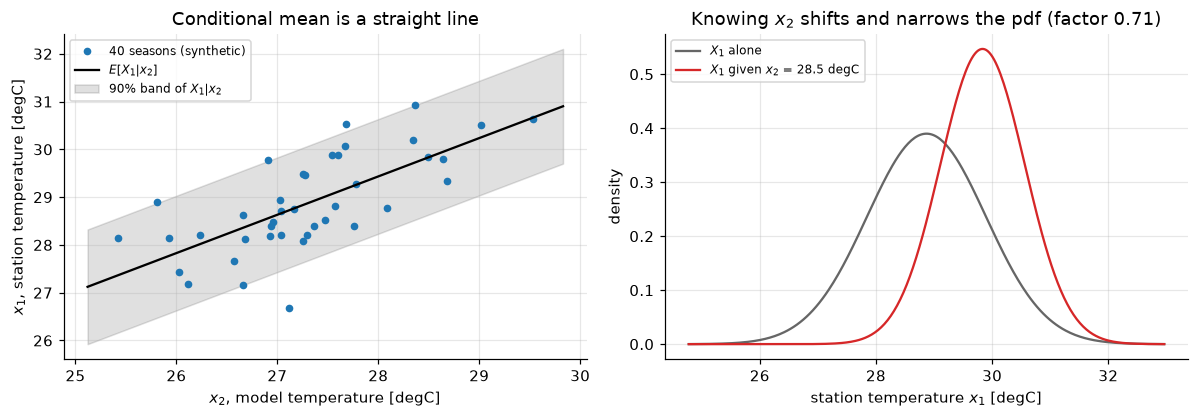

In [7]:
x_bar_1, x_bar_2 = x_1.mean(), x_2.mean()
s_1, s_2 = x_1.std(ddof=1), x_2.std(ddof=1)
gamma_12_hat = np.mean((x_1 - x_bar_1) * (x_2 - x_bar_2))                                                   # Eq. 2.58
rho_12_hat = np.sum((x_1 - x_bar_1) * (x_2 - x_bar_2)) / np.sqrt(np.sum((x_1 - x_bar_1)**2) * np.sum((x_2 - x_bar_2)**2))   # Eq. 2.59
x_2_given = 28.5
mean_cond = x_bar_1 + rho_12_hat * s_1 / s_2 * (x_2_given - x_bar_2)                                         # mean of Eq. 2.55
sd_cond = s_1 * np.sqrt(1 - rho_12_hat**2)
print(f"x_bar_1 = {x_bar_1:.3f}, x_bar_2 = {x_bar_2:.3f} degC;  s_1 = {s_1:.3f}, s_2 = {s_2:.3f} degC")
print(f"gamma_12_hat = {gamma_12_hat:.4f} degC^2,  rho_12_hat = {rho_12_hat:.4f}  (numpy: {np.corrcoef(x_1, x_2)[0, 1]:.4f})")
print(f"given x_2 = {x_2_given} degC:  E[X_1|x_2] = {mean_cond:.3f} degC,  sd = {sd_cond:.3f} degC  (unconditional sd {s_1:.3f})")
print("least-squares slope", round(np.polyfit(x_2, x_1, 1)[0], 4), "= rho * s_1/s_2 =", round(rho_12_hat * s_1 / s_2, 4))

fig, ax = plt.subplots(1, 2, figsize=(11, 3.9))
xl = np.linspace(x_2.min() - 0.3, x_2.max() + 0.3, 50)
line = x_bar_1 + rho_12_hat * s_1 / s_2 * (xl - x_bar_2)
ax[0].plot(x_2, x_1, "o", ms=4, label="40 seasons (synthetic)")
ax[0].plot(xl, line, "k", label="$E[X_1|x_2]$")
ax[0].fill_between(xl, line - 1.645 * sd_cond, line + 1.645 * sd_cond, color="k", alpha=0.12, label="90% band of $X_1|x_2$")
ax[0].set(xlabel="$x_2$, model temperature [degC]", ylabel="$x_1$, station temperature [degC]", title="Conditional mean is a straight line"); ax[0].legend(fontsize=8)
yy = np.linspace(x_bar_1 - 4 * s_1, x_bar_1 + 4 * s_1, 300)
ax[1].plot(yy, stats.norm.pdf(yy, x_bar_1, s_1), "0.4", label="$X_1$ alone")
ax[1].plot(yy, stats.norm.pdf(yy, mean_cond, sd_cond), "tab:red", label=f"$X_1$ given $x_2$ = {x_2_given} degC")
ax[1].set(xlabel="station temperature $x_1$ [degC]", ylabel="density", title=f"Knowing $x_2$ shifts and narrows the pdf (factor {np.sqrt(1 - rho_12_hat**2):.2f})"); ax[1].legend(fontsize=8)
fig.tight_layout();

## 2.3 Random simulation (Ch. 2.3)

### 2.3.1 Monte Carlo simulation and uniform random numbers

*Plain gloss:* to test a method we often need many plausible Januaries. **Monte Carlo simulation** draws many random samples from a fitted curve and studies them. It starts from uniform random numbers, made by a **linear congruential generator** that calculates whole numbers by a fixed rule,

$$x_j=(a+b\,x_{j-1})\bmod M,\qquad u_j=\frac{x_j}{M}\sim\mathrm{Unif}[0,1],\qquad (2.60,\ 2.62)$$

with increment $a$, multiplier $b$, large integer $M$ and a start value $x_0$ ("mod $M$" keeps the remainder after dividing by $M$). The numbers repeat after at most $M$ steps, so they are called pseudorandom; real generators use a very large $M$ such as $2^{32}$, for example $(a,b,M)=(1013904223,\,1664525,\,2^{32})$. *Small example by hand* with $a=3$, $b=5$, $M=16$, $x_0=7$:
$x_1=(3+5\cdot7)\bmod16=38\bmod16=6$, $u_1=6/16=0.3750$;
$x_2=(3+5\cdot6)\bmod16=33\bmod16=1$, $u_2=0.0625$;
$x_3=(3+5\cdot1)\bmod16=8$, $u_3=0.5000$;
$x_4=(3+5\cdot8)\bmod16=43\bmod16=11$, $u_4=0.6875$.

### 2.3.2 Simulation of probability distributions

The easiest way to turn $u$ into a draw from a target distribution is the **inverse transform**: because $u=F_X(X)$ is uniform, a draw is $x=F_X^{-1}(u)$. *Plain gloss:* read $u$ as a probability and take the rainfall that is not exceeded with that probability (the quantile). For the exponential the inverse is Eq. 2.23 with $F=u$,

$$x=-\alpha\ln(1-u).\qquad (2.66)$$

*Small example by hand,* using $\hat\alpha=39.0$ mm from the worked example and the four $u$ above:
$u_1$: $-39\ln(0.625)=-39(-0.4700)=18.33$ mm; $u_2$: $-39\ln(0.9375)=-39(-0.06454)=2.52$ mm; $u_3$: $-39\ln(0.5)=-39(-0.6931)=27.03$ mm; $u_4$: $-39\ln(0.3125)=-39(-1.1632)=45.36$ mm.
The draw for $u=0.5$ is the median, 27 mm, below the mean 39 mm because a few wet Januaries pull the mean up. For the gamma the inverse has no formula and is computed numerically. The cell below repeats the hand example, then draws from the gamma fitted above with the full-size generator.

*What this means for hydrology:* once a curve is fitted we can create as many synthetic Januaries as we like; this is how weather generators (Lecture 21) and quantile mapping (Lecture 18) work.

x_j = [ 6  1  8 11]  u = [0.375  0.0625 0.5    0.6875]  draws [mm] = [18.33  2.52 27.03 45.36]
10000 draws: mean 45.06 mm (fitted alpha*beta = 45.18), variance 331 (fitted alpha*beta^2 = 334),  F(x) back-check max error 1.4e-15
first eight draws [mm]: [16.  15.2 44.7 49.1 71.1 24.7 42.6 44.9]


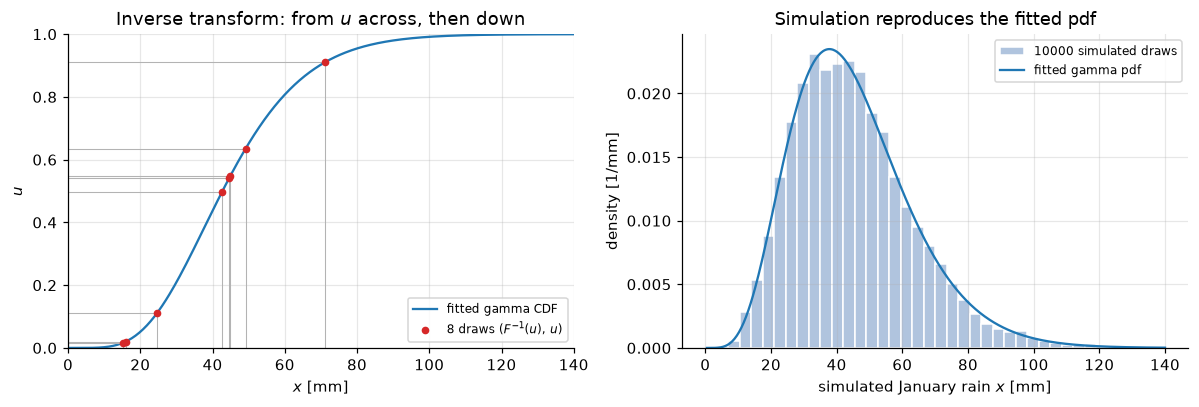

In [8]:
def lcg(a, b, M, x_0, N):
    # x_j = (a + b x_{j-1}) mod M  (Eq. 2.60); returns the N integers x_1 ... x_N
    out, x_j = [], x_0
    for _ in range(N):
        x_j = (a + b * x_j) % M
        out.append(x_j)
    return np.array(out)

# the hand example: integers, uniform numbers and exponential draws with alpha = 39 mm
x_lcg = lcg(3, 5, 16, 7, 4); u_hand = x_lcg / 16
print("x_j =", x_lcg, " u =", u_hand, " draws [mm] =", np.round(-x[:8].mean() * np.log(1 - u_hand), 2))
# the hand-example generator again, then the full-size generator (a, b, M) = (1013904223, 1664525, 2^32)
N = 10000
u_all = lcg(1013904223, 1664525, 2**32, 12345, N) / 2**32
x_sim = stats.gamma.ppf(u_all, alpha_mle, scale=beta_mle)           # x = F^-1(u)
print(f"{N} draws: mean {x_sim.mean():.2f} mm (fitted alpha*beta = {alpha_mle * beta_mle:.2f}), "
      f"variance {x_sim.var():.0f} (fitted alpha*beta^2 = {alpha_mle * beta_mle**2:.0f}),  F(x) back-check max error {np.abs(stats.gamma.cdf(x_sim, alpha_mle, scale=beta_mle) - u_all).max():.1e}")
print("first eight draws [mm]:", np.round(x_sim[:8], 1))

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
xc = np.linspace(0.5, 140, 400)
ax[0].plot(xc, stats.gamma.cdf(xc, alpha_mle, scale=beta_mle), "tab:blue", label="fitted gamma CDF")
for u_, x_ in zip(u_all[:8], x_sim[:8]):
    ax[0].plot([0, x_, x_], [u_, u_, 0], color="0.7", lw=0.7)
ax[0].plot(x_sim[:8], u_all[:8], "o", color="tab:red", ms=4, label="8 draws $(F^{-1}(u),\\,u)$")
ax[0].set(xlim=(0, 140), ylim=(0, 1), xlabel="$x$ [mm]", ylabel="$u$", title="Inverse transform: from $u$ across, then down"); ax[0].legend(fontsize=8, loc="lower right")
ax[1].hist(x_sim, bins=40, range=(0, 140), density=True, color="lightsteelblue", edgecolor="white", label=f"{N} simulated draws")
ax[1].plot(xc, stats.gamma.pdf(xc, alpha_mle, scale=beta_mle), "tab:blue", label="fitted gamma pdf")
ax[1].set(xlabel="simulated January rain $x$ [mm]", ylabel="density [1/mm]", title="Simulation reproduces the fitted pdf"); ax[1].legend(fontsize=8)
fig.tight_layout();

# Summary

- A variable is described by its **CDF** (chance of being at most $x$) and its **probability density** (the curve); the mean, variance and skewness describe centre, spread and tail.
- Use the **normal** for temperature, **exponential** or **gamma** for rain amounts, **lognormal** for flows and **GEV** or **Gumbel** for yearly maxima. In the book's GEV the shape is $\beta=-\xi$ of the usual convention.
- **Moments** match the mean and spread; **maximum likelihood** picks the parameter that makes the data most plausible. For the exponential both give $\hat\alpha=\bar x$.
- A **histogram** and plotting positions $i/(n+1)$ show the data on their own; always compare a fitted curve with them.
- Given the model value $x_2$, the station value is normal with mean $\mu_1+\rho(\sigma_1/\sigma_2)(x_2-\mu_2)$ and variance $\sigma_1^2(1-\rho^2)$.
- A congruential generator gives uniform numbers $u$, and $x=F_X^{-1}(u)$ turns them into random draws from a fitted curve.

**Companion workbook** `data/downscaling/lec17/lec17_worked_examples.xlsx` (blue = input, black = formula): `Exp_hand` is the by-hand example above, `Fit_26yr` the histogram, plotting positions and fits of Section 4, `Bivariate` Section 5, and `Data` holds the inputs.

# Check your understanding

1. An exponential curve has $\hat\alpha=40$ mm. Use Eq. 2.66 with $u=0.9$ to find the draw, and check it with $F_E(x)=1-e^{-x/\alpha}$. What does the answer mean in words?
2. A sample has $\bar x=8$ mm and $s=12$ mm. Give the gamma moment estimates $\hat\beta$ and $\hat\alpha$. Is the shape below or above 1, and what does the gamma figure in Section 2 show for that case?
3. For $\sigma_1=2$, $\sigma_2=1$ degC and $\rho=0.5$, what are the slope $\rho\sigma_1/\sigma_2$ of the conditional mean and the conditional standard deviation? By what fraction does knowing $x_2$ reduce the variance of $X_1$?

# Try it yourself

- Replace `january_precip.csv` by a real monthly or seasonal rainfall series and compare the exponential, gamma MOM and gamma MLE fits with the histogram.
- Change the seed `12345` or the generator constants in Section 6 and check how the simulated mean and variance move.
- Fit a lognormal ($\hat\zeta$ and $\hat\varsigma$ are the mean and standard deviation of $\ln x$) to the 26 totals and add it to the figure of Section 4.

```{note} Where this lecture differs from the book
- Eq. 2.20 (lognormal) prints $(x-\varsigma)^2$ and swaps the roles of $\zeta$ and $\varsigma$ relative to the text below it; we use $(\ln x-\zeta)^2/2\varsigma^2$ with $\zeta=E(\ln X)$, $\varsigma=\sqrt{\mathrm{Var}(\ln X)}$.
- Eq. 2.45 divides by $n_c-1$ but Example 2.3 then draws $n_c$ classes; we use $\Delta x=(x_{\rm Up}-x_{\rm Low})/n_c$ so that $n_c$ classes cover the range.
- Section 2.3.2 writes $u=F^{-1}(x)$; the inverse transform is $x=F^{-1}(u)$. Eqs. 2.64&ndash;2.65 print the exponential inverse with a location term; we use Eq. 2.66.
- The book's generator example ($a=2$, $b=1$, $M=7$) repeats after 7 numbers, so it only shows the recursion; we use $(3,5,16)$ by hand and a full-size generator for simulation.
```

```{note} Sources
Written for **CE524 Applied Hydroclimatology**. Notation and method formulations follow Chapter 2 (Statistical background) of Lee, T., & Singh, V. P. (2019). *Statistical Downscaling for Hydrological and Environmental Applications*. CRC Press: Section 2.1 (probability, distributions, moments and maximum likelihood, histogram and empirical distribution), Section 2.2 (multivariate normal, covariance, correlation) and Section 2.3 (Monte Carlo, uniform random numbers, inverse transform). The explanations, data, code and figures are original to this course; the book's examples and data are not reproduced. The harmony search algorithm of Section 2.4 is not covered.

All data are **synthetic**, generated with fixed random seeds (`data/downscaling/lec17/`), and do not describe any real station or model. The gamma-shape approximation in the spreadsheet is a standard closed-form approximation of the root of Eq. 2.43; the notebook solves the equation exactly.

Text under CC BY-SA 4.0, code additionally under the MIT License; full attribution in [CREDITS.md](https://github.com/drvivekhydro/hydroclimatology/blob/main/CREDITS.md).
```